# 01 Data audit, cleaning and foundational features

| Field | Value |
|---|---|
| **Purpose** | Check every column of the raw data for problems, decide how each problem is handled, and build the master table that every later notebook uses |
| **Assignment requirement** | Foundation for Tasks 1-8: trustworthy data before any analysis |
| **Inputs** | `jobs_clean.parquet`, `cleaning_log.csv`, `day_quality.csv`, `repeat_sensitivity.csv`, `eligibility_counts.csv`, `raw_column_profile.csv`, the raw CSV (for the unchanged-columns check) |
| **Outputs** | None; the pipeline step `clean` writes the files, this notebook explains and verifies them |
| **Build identity** | Printed by the first code cell |

**How to read this notebook.** The cleaning code lives in `src/job_market/steps/clean.py`, where automated tests check every rule. This notebook does not clean anything itself. It shows the evidence behind each rule, the rule itself, and how many rows it touches, then proves that the result is correct.

**The three promises of this step**

1. **No row is deleted.** 244,828 rows go in and 244,828 rows come out. Problems become *flag* columns (true/false markers) instead.
2. **No raw value changes.** The eight original columns stay exactly as they arrive. Cleaned values live in new columns next to them.
3. **No value is invented.** Missing pay or a missing country stays missing. Nothing is *imputed* (filled in with a guess such as an average).

Each later analysis picks its rows with *eligibility flags* (for example `eligible_for_hourly_rate_analysis`), so it is always clear which population a result describes.

In [1]:
from job_market.notebook import start

project = start()

RUN_ID: 20261003T124213Z-52b6a0b684
Source: data/raw/all_upwork_jobs_2024-02-07-2024-03-24.csv (244,828 rows)
Taxonomy version: 1.0
Verified outputs: 7 file(s), all hashes match
Environment: matches environment.yml


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from job_market.steps.ingest import read_raw

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)

jobs = project.read_parquet("jobs_clean.parquet")
cleaning_log = project.read_csv("cleaning_log.csv")
day_quality = project.read_csv("day_quality.csv", parse_dates=["date"])
repeat_sensitivity = project.read_csv("repeat_sensitivity.csv")
eligibility = project.read_csv("eligibility_counts.csv")
raw_profile = project.read_csv("raw_column_profile.csv")
rules = project.settings.section("cleaning")

RAW_COLUMNS = ["title", "link", "published_date", "is_hourly", "hourly_low", "hourly_high", "budget", "country"]
# Only the columns the audit needs, so the notebook never holds two full copies.
valid = jobs.loc[jobs["valid_job_record"], ["country", "country_known", "usable_title", "title_key", "posted_at",
                                             "pay_signature"] + [c for c in jobs.columns if c.startswith(("repeated_", "possible_"))]]

# Chart style: one quiet look for every figure in the project.
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
STATUS = {"complete": "#2a78d6", "intraday_gap": "#fab219", "incomplete": "#d03b3b"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10, "legend.frameon": False,
})
print(f"Master table: {len(jobs):,} rows x {jobs.shape[1]} columns")

Master table: 244,828 rows x 47 columns


## 1. Raw inspection

First, a plain look at the data as it arrives: its size, the type of each column, a few example rows, and how many distinct values each column holds.

In [3]:
print(f"Rows: {len(jobs):,}   Raw columns: {len(RAW_COLUMNS)}")
jobs[RAW_COLUMNS].head(5)

Rows: 244,828   Raw columns: 8


,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country
0,Experienced Media Buyer For Solar Pannel and Roofing installation companies.,https://www.upwork.com/jobs/Experienced-Media-Buyer-For-Solar-Pannel-and-Roofing-insta...,2024-02-17 09:09:54+00:00,False,NaN,NaN,500.0,None
1,Full Stack Developer,https://www.upwork.com/jobs/Full-Stack-Developer_%7E011604a02b364315a8?source=rss,2024-02-17 09:09:17+00:00,False,NaN,NaN,1100.0,United States
2,SMMA Bubble App,https://www.upwork.com/jobs/SMMA-Bubble-App_%7E0166a7749b263ff2e0?source=rss,2024-02-17 09:08:46+00:00,True,10.0,30.0,NaN,United States
3,Talent Hunter Specialized in Marketing,https://www.upwork.com/jobs/Talent-Hunter-Specialized-Marketing_%7E016285f94066dffb31?...,2024-02-17 09:08:08+00:00,True,NaN,NaN,NaN,United States
4,Data Engineer,https://www.upwork.com/jobs/Data-Engineer_%7E015c34d1bcadde8702?source=rss,2024-02-17 09:07:42+00:00,False,NaN,NaN,650.0,India


`raw_column_profile.csv` comes from the pipeline's ingest step, before any cleaning. `missing_pct` is the share of empty cells; `distinct_values` counts different values.

In [4]:
raw_profile

,column,dtype,non_missing,missing,missing_pct,distinct_values
0,title,object,244827,1,0.0004,205470
1,link,object,244827,1,0.0004,244827
2,published_date,object,244828,0,0.0000,233640
3,is_hourly,bool,244828,0,0.0000,2
4,hourly_low,float64,102422,142406,58.1657,114
5,hourly_high,float64,98775,146053,59.6553,227
6,budget,float64,103891,140937,57.5657,768
7,country,object,239751,5077,2.0737,212


**What the profile already tells us**

- Every job has a link and a timestamp except one row (checked in section 2.2).
- `hourly_low`, `hourly_high` and `budget` are each empty in roughly 40-60% of rows. Section 2.1 shows this is expected, not a data failure.
- `country` is empty in about 2% of rows.
- Links are unique: no job appears twice with the same link.

**Date coverage.** The file name says 7 February to 24 March 2024, but the timestamps say something more detailed:

In [5]:
months = jobs["posted_at"].dt.strftime("%Y-%m").value_counts().sort_index().rename("postings")
print(f"Earliest posting: {jobs['posted_at'].min():%Y-%m-%d %H:%M} UTC")
print(f"Latest posting:   {jobs['posted_at'].max():%Y-%m-%d %H:%M} UTC")
months.to_frame()

Earliest posting: 2023-11-02 09:22 UTC
Latest posting:   2024-03-24 14:16 UTC


,postings
posted_at,
2023-11,1
2023-12,10
2024-01,96
2024-02,101887
2024-03,142834


A few postings date from November 2023 to January 2024, far before the file's own start date. Almost all jobs fall in February and March. Section 2.4 checks which days the collector actually covered in full.

*All times in this project are UTC (Coordinated Universal Time), the time zone the source uses. Upwork is global, so no local time zone would be more correct (decision D-005).*

## 2. Data-quality audit

Each subsection checks one kind of problem and ends with what it means for cleaning. The rules themselves are collected in section 3.

### 2.1 Structural missingness: pay fields that do not apply

*Structural missingness* means a value is empty because the field does not apply to that row, not because something was lost. Upwork jobs are either **hourly** (paid per hour, with an optional rate range) or **fixed-price** (one total budget). So we expect hourly jobs never to have a budget and fixed-price jobs never to have hourly rates.

In [6]:
present = pd.DataFrame({
    "contract": np.where(jobs["is_hourly"], "hourly", "fixed-price"),
    "has hourly_low": jobs["hourly_low"].notna(),
    "has hourly_high": jobs["hourly_high"].notna(),
    "has budget": jobs["budget"].notna(),
})
present.groupby("contract").agg(["sum", "count"]).rename(columns={"sum": "filled", "count": "rows"})

has hourly_low         has hourly_high         has budget        
                    filled    rows          filled    rows     filled    rows
contract                                                                     
fixed-price              0  103891               0  103891     103891  103891
hourly              102422  140937           98775  140937          0  140937

**Finding.** The pattern is perfect: **no hourly job has a budget and no fixed-price job has an hourly rate** (`contract_pay_mismatch` is zero for every row). These empty cells are structural.

**Decision.** Never fill them in. Hourly pay and fixed-price pay are different measures (a rate per hour versus a total amount), so they are always analysed separately and never mixed into one "salary" column.

### 2.2 Genuine missingness: values that should exist but do not

Inside hourly jobs, the rate range is optional on Upwork, so some hourly jobs have one rate or none.

In [7]:
pay_info = jobs["pay_info"].value_counts().rename("rows").to_frame()
pay_info["share_pct"] = (100 * pay_info["rows"] / len(jobs)).round(2)
pay_info

,rows,share_pct
pay_info,,
fixed_budget,103891,42.43
hourly_range,98775,40.34
hourly_no_rate,38515,15.73
hourly_low_only,3647,1.49


In [8]:
print(f"Valid jobs without a country: {(~valid['country_known']).sum():,} "
      f"({100 * (~valid['country_known']).mean():.2f}%)")
print("\nRows that are not a usable job record:")
jobs.loc[~jobs["valid_job_record"], RAW_COLUMNS]

Valid jobs without a country: 5,076 (2.07%)

Rows that are not a usable job record:


,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country
38078,None,None,2024-02-20 16:28:05+00:00,True,NaN,NaN,NaN,None


**Findings.**

- About 27% of hourly jobs (`hourly_no_rate`) state no rate at all, and a few thousand state only a low rate (`hourly_low_only`).
- About 2% of jobs have no country.
- **One row is empty**: no title, no link, no country, only a timestamp and contract flag. It is not a usable job.

**Decisions.**

- No hourly midpoint is computed from a single rate, and no rate is guessed. Hourly-rate analysis uses only jobs with a complete range (`eligible_for_hourly_rate_analysis`).
- Missing countries stay missing. They are never grouped as a fake country called "Unknown", because two jobs with no country are not "from the same country".
- The empty row stays in the table for the audit trail, with `valid_job_record = False`, which keeps it out of every analysis.

### 2.3 Consistency checks

Rules that must always hold if the data is sound.

In [9]:
consistency = pd.Series({
    "hourly job with a budget, or fixed job with a rate": int(jobs["contract_pay_mismatch"].sum()),
    "hourly_low greater than hourly_high": int(jobs["rate_range_inverted"].sum()),
    "zero or negative pay values": int(((jobs[["hourly_low", "hourly_high", "budget"]] <= 0).any(axis=1)).sum()),
    "duplicate links": int(jobs["link"].dropna().duplicated().sum()),
    "fully identical rows": int(jobs[RAW_COLUMNS].duplicated().sum()),
    "hourly_low equal to hourly_high (a fixed rate, allowed)": int((jobs["hourly_low"] == jobs["hourly_high"]).sum()),
}, name="rows")
consistency.to_frame()

,rows
"hourly job with a budget, or fixed job with a rate",0
hourly_low greater than hourly_high,0
zero or negative pay values,0
duplicate links,0
fully identical rows,0
"hourly_low equal to hourly_high (a fixed rate, allowed)",96


**Finding.** Every hard rule holds: no mismatched pay fields, no inverted ranges, no zero or negative pay, no duplicate links and no duplicate rows. A low rate equal to the high rate simply means a single fixed hourly rate, which is legitimate.

**Decision.** No consistency repair is needed. The checks stay in the pipeline as flags (`contract_pay_mismatch`, `rate_range_inverted`), so a future data file with these problems is caught.

### 2.4 Collection completeness: which days are fully covered?

Later tasks count jobs per day to find trends. That only works on days when the collector ran the whole day. A day it covered only partly would look like a sudden drop in demand.

The pipeline rates every UTC calendar day (decision D-013):

- A **weak hour** has fewer postings than 30% of that day's median hour (an empty hour is always weak).
- A day is **incomplete** if it has fewer postings than 25% of a normal day, or more than two weak hours.
- A day with **one or two** weak hours has an **intraday gap**: mostly fine, flagged for checking.
- Every other day is **complete**.

The **time-series window** is the longest unbroken run of days that are not incomplete.

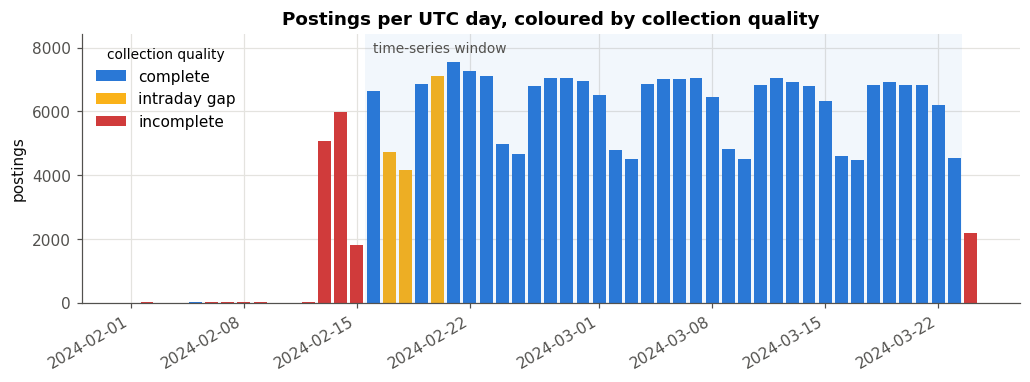

In [10]:
recent = day_quality[day_quality["date"] >= "2024-02-01"]
fig, ax = plt.subplots(figsize=(11, 3.6))
for status, color in STATUS.items():
    part = recent[recent["status"] == status]
    ax.bar(part["date"], part["postings"], width=0.8, color=color, label=status.replace("_", " "))
window = day_quality[day_quality["in_timeseries_window"]]
ax.axvspan(window["date"].min() - pd.Timedelta(hours=12), window["date"].max() + pd.Timedelta(hours=12),
           color=BLUE, alpha=0.06, lw=0)
ax.text(window["date"].min(), recent["postings"].max() * 1.04, "time-series window", color=MUTED, fontsize=9)
ax.set_title("Postings per UTC day, coloured by collection quality")
ax.set_ylabel("postings")
ax.set_ylim(0, recent["postings"].max() * 1.12)
ax.legend(loc="upper left", title="collection quality", title_fontsize=9)
fig.autofmt_xdate()
plt.show()

In [11]:
not_complete = day_quality[(day_quality["status"] != "complete") & (day_quality["date"] >= "2024-02-12")]
not_complete.assign(date=not_complete["date"].dt.strftime("%Y-%m-%d (%a)"))

,date,postings,weak_hours,status,in_timeseries_window
102,2024-02-12 (Mon),31,7,incomplete,False
103,2024-02-13 (Tue),5062,8,incomplete,False
104,2024-02-14 (Wed),5966,3,incomplete,False
105,2024-02-15 (Thu),1811,4,incomplete,False
107,2024-02-17 (Sat),4717,1,intraday_gap,True
108,2024-02-18 (Sun),4157,2,intraday_gap,True
110,2024-02-20 (Tue),7116,1,intraday_gap,True
143,2024-03-24 (Sun),2185,9,incomplete,False


In [12]:
earlier = day_quality[day_quality["date"] < "2024-02-12"]
print(f"Calendar days before 12 Feb: {len(earlier)}, with {earlier['postings'].sum()} postings in total "
      f"(at most {earlier['postings'].max()} on any day). All are incomplete.")
print(f"Time-series window: {window['date'].min():%d %b %Y} to {window['date'].max():%d %b %Y} ({len(window)} days)")

Calendar days before 12 Feb: 102, with 252 postings in total (at most 24 on any day). All are incomplete.
Time-series window: 16 Feb 2024 to 23 Mar 2024 (37 days)


**Findings.**

- Before **13 February**, the file holds only scattered postings (at most a few dozen per day): leftovers, not real collection.
- **13, 14 and 15 February** are incomplete: the collector starts in the early hours of the 13th, fades out late on the 14th and covers only part of the 15th.
- **24 March** stops at about 14:00 UTC.
- **16 February to 23 March** is an unbroken run of 37 usable days.
- Weekends are lower than weekdays (about 4,500 versus 7,000 postings). That is a real weekly pattern, not a collection problem, so the rule compares each day with its *own* median hour rather than with a weekday.

**Decision.** Daily counts and forecasts use only the window (`eligible_for_timeseries`). The jobs from incomplete days are still real jobs, so they stay in every analysis that does not count jobs per day: salary, countries, job categories and recommendations.

### 2.5 Intraday gaps: a closer look

Inside the window, three days have one or two weak hours. The bars below show each flagged day hour by hour; the line is the median profile of all complete days.

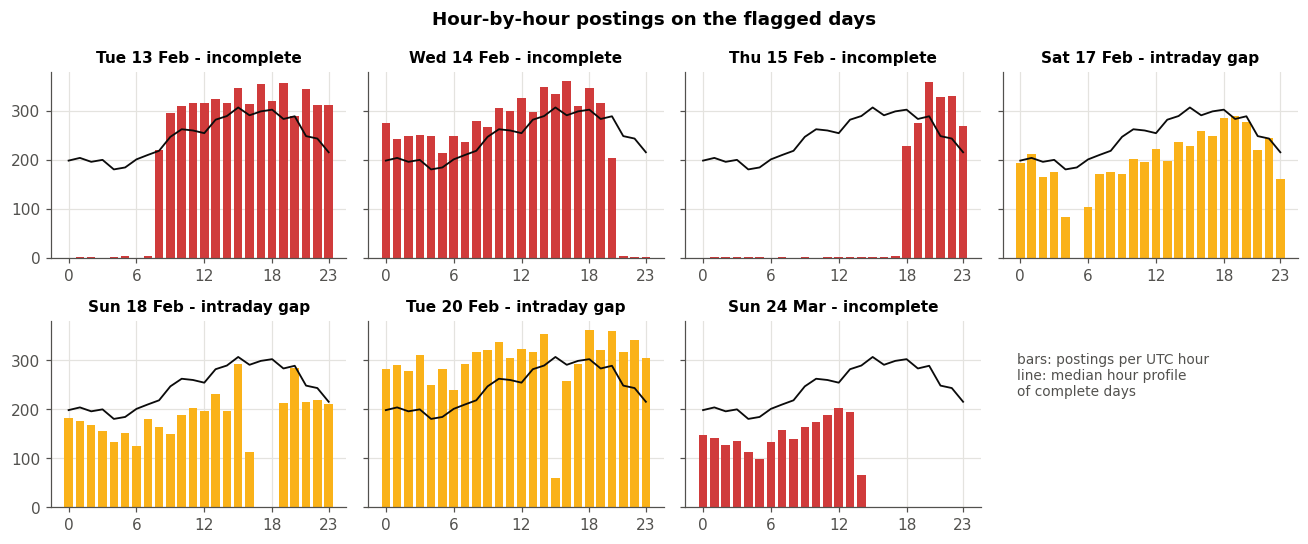

In [13]:
hours = (jobs.groupby(["posted_date", "hour"]).size()
             .unstack(fill_value=0)
             .reindex(columns=range(24), fill_value=0))
complete_days = day_quality.loc[day_quality["status"] == "complete", "date"]
typical = hours.loc[hours.index.isin(complete_days)].median()
show = ["2024-02-13", "2024-02-14", "2024-02-15", "2024-02-17", "2024-02-18", "2024-02-20", "2024-03-24"]
fig, axes = plt.subplots(2, 4, figsize=(12, 5), sharey=True)
for ax, day in zip(axes.flat, show):
    status = day_quality.set_index("date").loc[day, "status"]
    ax.bar(range(24), hours.loc[pd.Timestamp(day)], color=STATUS[status], width=0.75)
    ax.plot(range(24), typical, color=INK, lw=1.2)
    ax.set_title(f"{pd.Timestamp(day):%a %d %b} - {status.replace('_', ' ')}", fontsize=10)
    ax.set_xticks([0, 6, 12, 18, 23])
axes.flat[-1].axis("off")
axes.flat[-1].text(0.05, 0.6, "bars: postings per UTC hour\nline: median hour profile\nof complete days",
                   color=MUTED, fontsize=9, transform=axes.flat[-1].transAxes)
fig.suptitle("Hour-by-hour postings on the flagged days", fontweight="bold")
fig.tight_layout()
plt.show()

**Finding.** On the incomplete days, whole blocks of hours are empty or nearly empty. On 17, 18 and 20 February, a single hour (or two) drops far below the normal profile while the rest of the day looks normal.

**Decision.** The three intraday-gap days stay in the window, because removing them would break the run of days that forecasting needs. They carry `day_status = intraday_gap`, so later notebooks can check whether results change without them (a *sensitivity check*: repeating an analysis under a different reasonable choice to see whether the conclusion holds).

### 2.6 Repeated titles and possible reposts

39,000+ titles appear more than once. That can mean two very different things:

- **Repeated demand**: many different clients want the same popular role ("Virtual Assistant").
- **A repost**: one client posts the same job again, which double-counts one need.

The data has no client ID, so a repost can never be proven. The pipeline therefore uses two flags with different strength (decision D-016):

| Flag | Rule | Meaning |
|---|---|---|
| `repeated_title_<N>d` | same title key and same known country as an earlier posting within N days | repeated demand; an upper bound, **not** a repost estimate |
| `possible_repost_<N>d` | the same, plus the same contract type and the exact same pay terms | stronger evidence of a repost, still not proof |

The *title key* is the cleaned title in lower case with punctuation and emoji removed, so "Logo Design!!" and "logo design" match. Only informative pay counts: a fixed budget, or both ends of an hourly range. Two jobs that both lack pay never count as "same pay". The first posting of a chain is never flagged, so removing flagged rows in a sensitivity check keeps exactly one posting per chain.

**Why pay matters: the most repeated title groups.**

In [14]:
primary = rules["primary_repeat_window_days"]
groups = (valid[valid[f"repeated_title_{primary}d"]]
          .groupby(["title_key", "country"], observed=True)
          .agg(repeated_title=(f"repeated_title_{primary}d", "sum"),
               possible_repost=(f"possible_repost_{primary}d", "sum"),
               distinct_pay_terms=("pay_signature", "nunique"))
          .sort_values("repeated_title", ascending=False)
          .head(10))
groups

,,repeated_title,possible_repost,distinct_pay_terms
title_key,country,,,
social media manager,United States,245,45,93
virtual assistant,United States,228,52,67
logo design,United States,219,83,57
video editor,United States,136,18,62
graphic designer,United States,126,17,64
full stack developer,United States,91,17,56
appointment setter,United States,84,12,39
youtube video editor,United States,78,9,40
social media marketing,United States,70,4,38


"Social media manager" from the United States repeats hundreds of times within three-day windows, with dozens of different pay terms. That is many clients hiring for a popular role, not one client reposting. If the title-only flag were treated as duplicates, later demand analysis would wrongly shrink exactly the most popular roles. Requiring the same pay removes most of these matches.

**How long between repeats?** If reposts happened at one typical delay, the gaps would show a clear break. The chart shows the time between each posting and the previous one with the same title key and country.

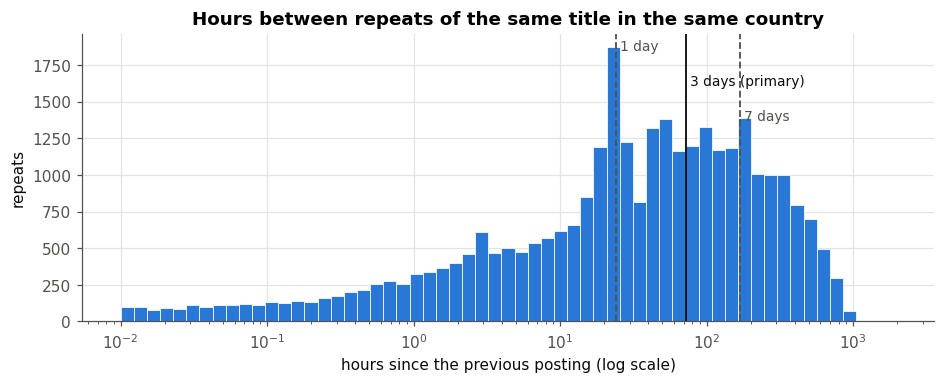

Median gap: 37 hours;  within 3 days: 63% of repeats


In [15]:
base = valid[valid["country_known"] & valid["usable_title"]].sort_values("posted_at")
gaps_h = (base.groupby(["title_key", "country"], observed=True)["posted_at"].diff()
              .dropna().dt.total_seconds() / 3600)
gaps_h = gaps_h[gaps_h > 0]
fig, ax = plt.subplots(figsize=(10, 3.4))
bins = np.logspace(np.log10(max(gaps_h.min(), 0.01)), np.log10(gaps_h.max()), 60)
ax.hist(gaps_h, bins=bins, color=BLUE, edgecolor="white", linewidth=0.5)
ax.set_xscale("log")
for days, label, height in [(1, "1 day", 0.94), (3, "3 days (primary)", 0.82), (7, "7 days", 0.70)]:
    ax.axvline(days * 24, color=INK if days == 3 else MUTED, lw=1.2, ls="-" if days == 3 else "--")
    ax.text(days * 24 * 1.07, ax.get_ylim()[1] * height, label, color=INK if days == 3 else MUTED, fontsize=9)
ax.set_title("Hours between repeats of the same title in the same country")
ax.set_xlabel("hours since the previous posting (log scale)")
ax.set_ylabel("repeats")
plt.show()
print(f"Median gap: {gaps_h.median():.0f} hours;  within 3 days: {100 * (gaps_h <= 72).mean():.0f}% of repeats")

In [16]:
repeat_sensitivity

,flag,window_days,rows_flagged,share_of_valid_rows_pct,share_with_short_title_pct
0,repeated_title_1d,1,13128,5.36,45.35
1,possible_repost_1d,1,6143,2.51,23.86
2,repeated_title_3d,3,19714,8.05,46.41
3,possible_repost_3d,3,9192,3.75,25.07
4,repeated_title_7d,7,24790,10.13,47.52
5,possible_repost_7d,7,11351,4.64,26.82


**Findings.**

- The gaps spread from minutes to weeks with **no natural break** (no empty valley that separates "reposts" from "new demand"), so no window can be "discovered" from the data. **Three days** is a reasoned choice: it captures most short-term repeats without reaching into the following weeks. The 1-day and 7-day versions exist to show how much the choice matters.
- There is one clear **spike at about 24 hours**: some titles reappear one day later, which fits clients (or posting tools) that repost daily. The 3-day window includes it.
- The pay-matched flag marks well under half as many rows as the title-only flag at every window, and far fewer of its rows have short, generic titles (three words or fewer).

**Decision.** `possible_repost_3d` is the primary flag for sensitivity checks on demand counts. `repeated_title_*` describes repeated demand and is never used to remove rows. Nothing is deleted.

### 2.7 Text defects in titles

In [17]:
text_issues = pd.Series({
    "HTML entities such as &amp; (decoded)": int(jobs["title_had_html_entities"].sum()),
    "mojibake (repaired)": int(jobs["title_mojibake_repaired"].sum()),
    "damaged text that cannot be repaired (flagged)": int(jobs["title_mojibake_unrepaired"].sum()),
    "Unicode replacement character (flagged)": int(jobs["title_has_replacement_char"].sum()),
    "contains emoji (kept)": int(jobs["title_has_emoji"].sum()),
}, name="titles")
text_issues.to_frame()

,titles
HTML entities such as &amp; (decoded),10130
mojibake (repaired),208
damaged text that cannot be repaired (flagged),25
Unicode replacement character (flagged),32
contains emoji (kept),894


- **HTML entities** are web codes for special characters: `&amp;` means `&`, `&quot;` means `"`. Left as they are, "SEO &amp; ads" and "SEO & ads" would count as different titles.
- **Mojibake** is garbled text produced when text stored as UTF-8 is read with the wrong character table (a Windows *code page*): "für" turns into "fÃ¼r", and an emoji turns into "ğŸš€". The repair reverses exactly that mistake, and only when the reversal produces valid text. Correct text such as "für" cannot pass that test, so it is never changed.
- Some titles were damaged twice or lost bytes at the source; they cannot be repaired and are flagged instead.

Before and after, for a few examples:

In [18]:
examples = pd.concat([
    jobs[jobs["title_had_html_entities"]].sample(3, random_state=1),
    jobs[jobs["title_mojibake_repaired"]].sample(4, random_state=1),
    jobs[jobs["title_mojibake_unrepaired"]].sample(2, random_state=1),
])[["title", "title_clean"]]
examples

,title,title_clean
241992,Social Media &amp; Online Community Manager,Social Media & Online Community Manager
222073,Passionate video editor for Paid Social (Meta &amp; TikTok),Passionate video editor for Paid Social (Meta & TikTok)
52130,Content Writer: Join our team for annual writing opportunities&quot;,"Content Writer: Join our team for annual writing opportunities"""
37373,Locutores y editores de novelas en espaÃ±ol,Locutores y editores de novelas en español
31521,Native Turkish writerâ€™s,Native Turkish writer’s
33129,Medical/research review writer needed for website article (telehealth company blog)â€”...,Medical/research review writer needed for website article (telehealth company blog)— M...
38906,Busco Editor de Video ðŸŽ¬,Busco Editor de Video 🎬
28319,Design and Layout for Printable Booklet (5.5â€� x 8.5â€�),Design and Layout for Printable Booklet (5.5â€� x 8.5â€�)
26904,â�—ï¸�â�—ï¸�â�—ï¸� ATTENTIONâ�—ï¸�â�—ï¸�â�—ï¸� Creative DTC Email Designer WANTED ðŸŽ¨...,â�—ï ̧�â�—ï ̧�â�—ï ̧� ATTENTIONâ�—ï ̧�â�—ï ̧�â�—ï ̧� Creative DTC Email Designer WANTE...


**Language.** A language label per title looks useful, so the `langdetect` library was tested during design. On plain-English titles it gave confidently wrong answers: "PHP LARAVEL MYSQL Expert" as Catalan and "Social media Manager" as Italian, both at 90% confidence or more. Short job titles full of product names defeat statistical language guessing (decision D-018 has the measurement).

Instead, the pipeline records `title_script`: **which alphabet** a title is written in. That is an exact property of the characters, not a guess. Its limit: Spanish or German titles written in the Latin alphabet are not separated from English.

In [19]:
jobs["title_script"].value_counts().rename("titles").to_frame()

,titles
title_script,
latin,244639
cyrillic,87
mixed,72
arabic,16
greek,6
cjk,5
devanagari,1
hebrew,1
none,1


**Decision.** Titles are cleaned into `title_clean` (entities decoded, mojibake repaired, *NFKC normalisation*, which turns visual variants such as full-width letters into their standard form, and repeated spaces collapsed). Case and punctuation stay, because they carry meaning ("C++", "UI/UX"). The raw `title` is never changed. No job is excluded because of its alphabet or its emoji.

### 2.8 Pay extremes

Pay data always has a long right tail: a few very well-paid jobs sit far above the rest. Those are real, and an automatic outlier rule such as IQR would wrongly mark many of them as errors. Some values, however, look like placeholders. The charts use a log scale (each grid step is ten times the previous one), so both the bulk and the tail are visible.

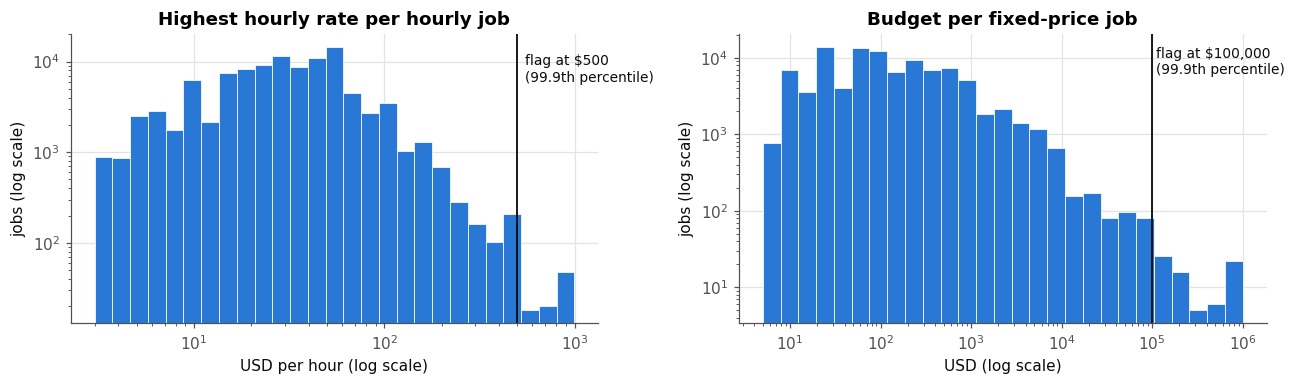

In [20]:
from job_market.steps.clean import add_pay_columns  # noqa: F401  (documents where the thresholds come from)

rate_cut = project.counts["extreme_hourly_rate_threshold"]
budget_cut = project.counts["extreme_budget_threshold"]
top_rate = jobs["hourly_high"].fillna(jobs["hourly_low"])[jobs["is_hourly"]].dropna()
budgets = jobs.loc[~jobs["is_hourly"], "budget"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, values, cut, title, unit in [
    (axes[0], top_rate, rate_cut, "Highest hourly rate per hourly job", "USD per hour"),
    (axes[1], budgets, budget_cut, "Budget per fixed-price job", "USD"),
]:
    bins = np.logspace(np.log10(values.min()), np.log10(values.max()), 28)
    ax.hist(values, bins=bins, color=BLUE, edgecolor="white", linewidth=0.5)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.axvline(cut, color=INK, lw=1.2)
    ax.text(cut * 1.1, ax.get_ylim()[1] * 0.3, f"flag at ${cut:,.0f}\n(99.9th percentile)", fontsize=9, color=INK)
    ax.set_title(title)
    ax.set_xlabel(f"{unit} (log scale)")
    ax.set_ylabel("jobs (log scale)")
fig.tight_layout()
plt.show()

In [21]:
def top_values(series, cut):
    tail = series[series >= cut].value_counts().sort_index(ascending=False)
    return tail.rename("jobs").to_frame()

print("Hourly rates at or above the flag:")
display(top_values(top_rate, rate_cut).head(8))
print("Budgets at or above the flag:")
display(top_values(budgets, budget_cut).head(8))

Hourly rates at or above the flag:


,jobs
hourly_high,
999.0,35
995.0,1
990.0,5
950.0,2
920.0,1
900.0,1
825.0,1
820.0,2


Budgets at or above the flag:


,jobs
budget,
1000000.0,10
999999.0,7
997128.0,1
996921.0,1
900000.0,1
800000.0,1
700000.0,1
600000.0,2


**Findings.**

- Hourly rates have spikes at round numbers and at **$999/hour**, which looks like a "maximum" placeholder rather than a real offer.
- Budgets reach **$999,999** and **$1,000,000**, which look like placeholders too.
- But the data cannot prove which high values are fake. A $500/hour expert consultant or a $100,000 software project is plausible.

**Decision.** Flag values at or above the 99.9th percentile (a *percentile* is the value below which that share of the data falls; the 99.9th percentile leaves only the top 0.1% above it). The flags are `extreme_hourly_rate_flag` and `extreme_budget_flag`. Raw values are never removed or *clipped* (capped at a lower number). Every pay analysis reports its result with and without the flagged jobs, and uses medians, which a few extreme values cannot move much.

### 2.9 Country completeness

In [22]:
countries = valid["country"].value_counts()
print(f"Distinct countries: {countries.size}")
print(f"Countries with fewer than 30 jobs: {(countries < 30).sum()}")
print(f"Top 10 countries hold {100 * countries.head(10).sum() / valid['country_known'].sum():.1f}% of jobs with a country")
countries.head(10).rename("jobs").to_frame()

Distinct countries: 212
Countries with fewer than 30 jobs: 96
Top 10 countries hold 75.4% of jobs with a country


,jobs
country,
United States,99834
United Kingdom,19149
India,15835
Australia,12618
Canada,11658
Pakistan,5291
Germany,4844
Netherlands,4435
United Arab Emirates,4039


**Finding.** Country is the location of the *client* posting the job. The United States dominates, and many countries have only a handful of jobs.

**Decision.** No country is merged or renamed here. Task 4 (rates by country) sets a minimum number of jobs per country before ranking it, so a country with five jobs is never presented as a reliable average.

## 3. Cleaning decisions

Every rule from section 2 in one table: the problem, the evidence, the decision, and how many rows it touches. The pipeline writes this table (`cleaning_log.csv`), so its numbers always match the current build.

In [23]:
with pd.option_context("display.max_colwidth", 140):
    display(cleaning_log.set_index("rule_id"))

,problem,evidence,decision,rows_affected
rule_id,,,,
C01,Empty record,"Title, link and country are all empty in the same row.",Keep the row; valid_job_record = False excludes it from every analysis.,1
C02,Budget is empty for hourly jobs; rates are empty for fixed-price jobs,"140,937 of 140,937 hourly jobs lack a budget and 103,891 of 103,891 fixed-price jobs lack rates; contract_pay_mismatch is 0.","Structural: the field does not apply to that contract type, so every valid row has one. Never filled in; hourly and fixed-price pay are ...",244827
C03,Hourly jobs without a complete rate range,"3,647 have only a low rate and 38,515 have no rate.",Genuinely missing. No midpoint and no imputation; excluded from hourly-rate analysis only.,42162
C04,Missing country,"5,076 valid jobs have no country.",Kept as missing (never 'Unknown' matched to 'Unknown'); excluded only where country is needed.,5076
C05,HTML entities in titles,"Titles contain codes such as &amp; and &quot; instead of & and "".",Decoded in title_clean; the raw title is kept.,10130
C06,Mojibake in titles,"UTF-8 text decoded with a Windows code page, for example 'fÃ¼r' for 'für'.",Repaired in title_clean only when re-encoding the text decodes cleanly as UTF-8; the raw title is kept.,208
C07,Unrecoverable characters,"Titles contain the Unicode replacement character, or damaged text that no single repair fixes; the original letters are lost at the source.","Flagged (title_has_replacement_char, title_mojibake_unrepaired); the rest of the title stays usable.",33
C08,Extreme hourly rates,"Highest rate at or above the 99.9% quantile ($500/hr), including placeholder-like values such as $999.",Flagged (extreme_hourly_rate_flag); raw values kept; analyses report results with and without them.,277
C09,Extreme fixed-price budgets,"Budget at or above the 99.9% quantile ($100,000), including values such as $999,999 and $1,000,000.",Flagged (extreme_budget_flag); raw values kept; analyses report results with and without them.,119


## 4. Foundational features

These columns are added now because almost every later notebook needs them. Features that belong to one task (text vectors, categories, model inputs) are built in that task's notebook.

In [24]:
features = pd.DataFrame([
    ("row_id", "position of the row in the raw file; a stable ID for every job"),
    ("title_clean", "title with HTML entities decoded, mojibake repaired, NFKC normalised, spaces collapsed"),
    ("title_key", "lower-case letters and digits of the title; used only to match repeated titles"),
    ("title_word_count, title_char_count", "title length in words and characters"),
    ("title_script", "alphabet of the title: latin, cyrillic, arabic, cjk, ..., mixed or none"),
    ("title_had_html_entities, title_mojibake_repaired", "what the cleaning changed"),
    ("title_mojibake_unrepaired, title_has_replacement_char, title_has_emoji", "text-quality flags"),
    ("posted_at", "timestamp in UTC"),
    ("posted_date, weekday, hour, iso_week", "UTC calendar day, day name, hour 0-23, ISO week such as 2024-W09"),
    ("contract_type", "hourly or fixed"),
    ("pay_info", "hourly_range, hourly_low_only, hourly_no_rate or fixed_budget"),
    ("hourly_mid", "middle of the hourly range; only when both ends exist"),
    ("pay_signature", "exact pay terms used to match possible reposts; empty when pay is not informative"),
    ("extreme_hourly_rate_flag, extreme_budget_flag", "pay at or above the 99.9th percentile"),
    ("contract_pay_mismatch, rate_range_inverted", "consistency flags (all false in this data)"),
    ("country_known", "the job has a country"),
    ("day_status, in_timeseries_window", "collection quality of the posting day; inside the 37-day window"),
    ("repeated_title_{1,3,7}d, possible_repost_{1,3,7}d", "repeat and possible-repost flags"),
    ("valid_job_record, usable_title", "the row is a real job; the title has letters or digits"),
    ("eligible_for_*", "which analysis may use the row"),
], columns=["column", "meaning"])
features

,column,meaning
0,row_id,position of the row in the raw file; a stable ID for every job
1,title_clean,"title with HTML entities decoded, mojibake repaired, NFKC normalised, spaces collapsed"
2,title_key,lower-case letters and digits of the title; used only to match repeated titles
3,"title_word_count, title_char_count",title length in words and characters
4,title_script,"alphabet of the title: latin, cyrillic, arabic, cjk, ..., mixed or none"
5,"title_had_html_entities, title_mojibake_repaired",what the cleaning changed
6,"title_mojibake_unrepaired, title_has_replacement_char, title_has_emoji",text-quality flags
7,posted_at,timestamp in UTC
8,"posted_date, weekday, hour, iso_week","UTC calendar day, day name, hour 0-23, ISO week such as 2024-W09"
9,contract_type,hourly or fixed


*ISO week*: the international week number, where weeks start on Monday. It lets later notebooks group days into weeks without ambiguity.

In [25]:
jobs.loc[jobs["valid_job_record"], ["title_clean", "posted_at", "weekday", "hour", "iso_week", "contract_type",
                                    "pay_info", "hourly_mid", "country", "day_status"]].sample(5, random_state=7)

,title_clean,posted_at,weekday,hour,iso_week,contract_type,pay_info,hourly_mid,country,day_status
213700,Immediate Hire - Need Career-Oriented Gen Z'ers for Survey,2024-03-16 13:20:29+00:00,Saturday,13,2024-W11,fixed,fixed_budget,NaN,United States,complete
210545,Mobile game development,2024-03-17 06:56:33+00:00,Sunday,6,2024-W11,hourly,hourly_range,20.0,Netherlands,complete
8193,Simple copy and paste data from a webpage into excel,2024-02-17 12:42:11+00:00,Saturday,12,2024-W07,hourly,hourly_range,16.5,Pakistan,intraday_gap
237451,"GHL, WordPress, Zapier Expert Needed",2024-03-21 01:04:38+00:00,Thursday,1,2024-W12,hourly,hourly_no_rate,NaN,United States,complete
216281,I'm looking a freelancer who can assist me with Bookkeeping and Handle accounts,2024-03-22 09:57:33+00:00,Friday,9,2024-W12,fixed,fixed_budget,NaN,India,complete


## 5. Post-clean validation

Claims are only as good as their checks. Each check below stops the notebook with an error if it fails, so a saved, fully executed copy of this notebook is itself the proof that every check passes.

In [26]:
raw = read_raw(project.settings.path("raw_csv"), RAW_COLUMNS)
checks = {}

# 1. Same rows in and out.
checks["rows in = rows out"] = len(raw) == len(jobs)

# 2. Raw columns unchanged, value by value.
for column in RAW_COLUMNS:
    pd.testing.assert_series_equal(raw[column], jobs[column], check_dtype=False)
checks["8 raw columns unchanged"] = True

# 3. Flags are internally consistent.
for days in rules["repeat_windows_days"]:
    assert not (jobs[f"possible_repost_{days}d"] & ~jobs[f"repeated_title_{days}d"]).any()
assert not (jobs["possible_repost_1d"] & ~jobs["possible_repost_3d"]).any()
assert not (jobs["possible_repost_3d"] & ~jobs["possible_repost_7d"]).any()
checks["possible repost implies repeated title; 1d within 3d within 7d"] = True
checks["midpoint exists exactly for complete hourly ranges"] = bool(
    (jobs["hourly_mid"].notna() == (jobs["pay_info"] == "hourly_range")).all())
has_mid = jobs["hourly_mid"].notna()
checks["midpoint lies inside the range"] = bool(
    jobs.loc[has_mid, "hourly_mid"].between(jobs.loc[has_mid, "hourly_low"], jobs.loc[has_mid, "hourly_high"]).all())
checks["no eligible row is invalid"] = bool(
    not (jobs.filter(like="eligible_for_").any(axis=1) & ~jobs["valid_job_record"]).any())
checks["time-series rows lie inside the window"] = bool(
    jobs.loc[jobs["eligible_for_timeseries"], "posted_date"].between(window["date"].min(), window["date"].max()).all())
checks["no row without pay is a possible repost"] = bool(
    not (jobs["possible_repost_7d"] & (jobs["pay_signature"] == "")).any())

# 4. Types survive the Parquet round trip.
flags = [c for c in jobs.columns if c.startswith(("eligible_", "possible_", "repeated_", "extreme_", "title_has"))]
checks["all flag columns are true/false"] = all(jobs[c].dtype == bool for c in flags)
checks["posted_at is a UTC timestamp"] = str(jobs["posted_at"].dt.tz) == "UTC"
checks["timestamps match the raw text"] = bool(
    (jobs["posted_at"].dt.strftime("%Y-%m-%d %H:%M:%S+00:00") == raw["published_date"]).all())

del raw  # free the second copy of the data before continuing
results = pd.Series(checks, name="passes").to_frame()
assert results["passes"].all(), results[~results["passes"]]
results

C:\Users\manis\AppData\Local\Temp\ipykernel_2304\3373081751.py:9: FutureWarning: Mismatched null-like values nan and None found. In a future version, pandas equality-testing functions (e.g. assert_frame_equal) will consider these not-matching and raise.
  pd.testing.assert_series_equal(raw[column], jobs[column], check_dtype=False)


,passes
rows in = rows out,True
8 raw columns unchanged,True
possible repost implies repeated title; 1d within 3d within 7d,True
midpoint exists exactly for complete hourly ranges,True
midpoint lies inside the range,True
no eligible row is invalid,True
time-series rows lie inside the window,True
no row without pay is a possible repost,True
all flag columns are true/false,True
posted_at is a UTC timestamp,True


In [27]:
eligibility.set_index("flag")

,rows,share_of_all_rows_pct
flag,,
eligible_for_text_analysis,244827,100.00
eligible_for_hourly_rate_analysis,98775,40.34
eligible_for_budget_analysis,103891,42.43
eligible_for_timeseries,229520,93.75
valid_job_record,244827,100.00


The numbers quoted in this notebook's text are checked here too, so the words cannot drift away from the data:

In [28]:
day_gaps = gaps_h[(gaps_h > 20) & (gaps_h <= 28)]
claims = {
    "244,828 rows": len(jobs) == 244_828,
    "spike at about 24 hours": len(day_gaps) > 1.5 * len(gaps_h[(gaps_h > 28) & (gaps_h <= 36)]),
    "one empty record": int((~jobs["valid_job_record"]).sum()) == 1,
    "window 16 Feb - 23 Mar, 37 days": (window["date"].min() == pd.Timestamp("2024-02-16")
                                        and window["date"].max() == pd.Timestamp("2024-03-23") and len(window) == 37),
    "gap days 17, 18, 20 Feb": sorted(day_quality.loc[day_quality["status"] == "intraday_gap", "date"]
                                      .dt.strftime("%d").tolist()) == ["17", "18", "20"],
    "no hourly budget, no fixed rate": int(jobs["contract_pay_mismatch"].sum()) == 0,
    "~27% of hourly jobs state no rate": round(100 * (jobs["pay_info"] == "hourly_no_rate").sum() / jobs["is_hourly"].sum()) == 27,
    "~2% of jobs have no country": round(100 * (~valid["country_known"]).mean()) == 2,
    "$999/hour present": bool((top_rate == 999).any()),
    "$999,999 and $1,000,000 budgets present": bool(budgets.isin([999_999, 1_000_000]).sum() >= 2),
    "pay-matched flag < half the title flag": all(
        repeat_sensitivity.set_index("flag").loc[f"possible_repost_{d}d", "rows_flagged"]
        < 0.5 * repeat_sensitivity.set_index("flag").loc[f"repeated_title_{d}d", "rows_flagged"]
        for d in rules["repeat_windows_days"]),
}
claims = pd.Series(claims, name="true").to_frame()
assert claims["true"].all(), claims[~claims["true"]]
claims

,true
"244,828 rows",True
spike at about 24 hours,True
one empty record,True
"window 16 Feb - 23 Mar, 37 days",True
"gap days 17, 18, 20 Feb",True
"no hourly budget, no fixed rate",True
~27% of hourly jobs state no rate,True
~2% of jobs have no country,True
$999/hour present,True
"$999,999 and $1,000,000 budgets present",True


## 6. Summary

**What changed.** Nothing in the original eight columns. The master table adds cleaned titles, UTC time features, pay structure, data-quality flags, repeat flags and eligibility flags: one row per raw row.

**What the cleaning found.**

- The pay fields are structurally clean: hourly and fixed-price jobs never mix fields, and no range is inverted. The real gaps are optional fields: about 27% of hourly jobs state no rate, and about 2% of jobs have no country.
- Collection was complete only from **16 February to 23 March (37 days)**. Earlier and later days are partial.
- Titles needed real cleaning: thousands of HTML entities and a few hundred garbled (mojibake) titles.
- Pay has a genuine long tail plus some placeholder-like values ($999/hour, $1,000,000 budgets).
- Repeated titles are mostly **repeated demand for popular roles**, not reposts. Matching exact pay separates the two.

**What each later analysis uses**

| Analysis | Rows | Excludes |
|---|---|---|
| Text and categories (Tasks 1, 2, 5) | `eligible_for_text_analysis` | the one empty record |
| Hourly pay (Tasks 1, 4) | `eligible_for_hourly_rate_analysis` | hourly jobs without a complete range; fixed-price jobs |
| Fixed-price budgets (Task 1) | `eligible_for_budget_analysis` | hourly jobs |
| Daily counts and forecasts (Tasks 2, 3, 6, 7, 8) | `eligible_for_timeseries` | jobs from incomplete collection days |

**What later notebooks must test.** Each pay result is reported with and without extreme values. Each demand result is checked without `possible_repost_3d` rows and without the three intraday-gap days. If a conclusion changes, the notebook says so.